# Предобработка данных и регрессия на датасете «House Prices»

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** House Prices – Advanced Regression Techniques  
**Выполнил:** Иванов Семён Иванович  
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич 
**Ссылка на репозиторий:** https://github.com/IvanovSimoon/ml-course-ivanov  
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 13.10.2026

## Введение

**Задача:** регрессия — предсказать цену продажи дома (непрерывная величина в долларах, от $34 900 до $755 000).

**ML-проект для регрессии** — это последовательность этапов: сбор данных → EDA → предобработка (пропуски, выбросы) → feature engineering → обучение → оценка → интерпретация → деплой. Каждый шаг влияет на итоговое качество и интерпретируемость модели.

**Почему регрессия, а не классификация:** целевая переменная `SalePrice` — непрерывная величина в долларах, а не дискретный класс. Классификация предсказывает метку (0/1, «кошка/собака»), регрессия — числовое значение.

**Важная метрика:** RMSE (Root Mean Squared Error) — основная метрика соревнования Kaggle. RMSE измеряется в тех же единицах, что и целевая (доллары), и штрафует большие ошибки сильнее, чем MAE. Дополнительно смотрим R² — долю объяснённой дисперсии.

**Цель работы:**
1. Провести полный EDA датасета House Prices.
2. Обучить 4+ модели и достичь R² ≥ 0.90.
3. Реализовать функцию предсказания цены нового дома.

**Актуальность:** задача оценки недвижимости — классическая прикладная задача ML. Датасет House Prices содержит реалистичные сложности: 19 столбцов с пропусками, скошенная целевая, выбросы, мультиколлинеарность.

## Теоретическая часть

### Регрессия

Регрессия — задача машинного обучения, в которой нужно предсказать **непрерывную** числовую величину. Отличие от классификации: там целевая переменная — дискретная метка (0/1, «спам/не спам»), здесь — число (цена, температура, рост). Примеры регрессии: прогноз цены недвижимости, курса акций, температуры, спроса на товар. Для обучения моделей минимизируют функцию потерь — обычно MSE (Mean Squared Error).

### Пропуски (NaN)

Пропуски возникают по разным причинам: ошибка ввода, отказ респондента, потеря данных. Различают три типа: **MCAR** (Missing Completely At Random) — пропуски полностью случайны, **MAR** (Missing At Random) — зависят от других признаков, **MNAR** (Missing Not At Random) — зависят от самого пропущенного значения. В House Prices есть все три типа. Стратегии: удаление (если пропусков мало), заполнение константой/средним/медианой/модой, заполнение по группам, предсказание моделью.

### Регуляризация

Регуляризация — добавление штрафа к функции потерь для борьбы с переобучением и мультиколлинеарностью. **Ridge (L2)** добавляет штраф `α * Σw²` — уменьшает веса, но не обнуляет. **Lasso (L1)** добавляет `α * Σ|w|` — обнуляет неинформативные признаки (автоматический feature selection). **ElasticNet** комбинирует L1 и L2 через параметр `l1_ratio`. Чем больше `α`, тем сильнее регуляризация.

### Логарифмирование

Если целевая переменная имеет правое смещение (skew > 1), это означает длинный хвост из больших значений. Модели регрессии (особенно линейные) предполагают нормальность остатков — при скошенности они работают хуже. `np.log1p(y) = log(1 + y)` сжимает большие значения, приближая распределение к нормальному. `np.expm1(x) = exp(x) - 1` — обратное преобразование для получения предсказаний в долларах.

### Feature Engineering

Feature Engineering — создание новых признаков из существующих на основе доменных знаний. Примеры: `TotalSF = TotalBsmtSF + 1stFlrSF + 2ndFlrSF` (общая площадь), `HouseAge = YrSold - YearBuilt` (возраст дома), `HasGarage = (GarageArea > 0)` (бинарный признак). Хорошо продуманные признаки часто дают больше прироста качества, чем смена модели.

### Метрики регрессии

$$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

$$RMSE = \sqrt{MSE}, \quad MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

| Метрика | Что показывает | Единицы | Когда важна |
|---|---|---|---|
| MSE | Среднеквадратичная ошибка | $² | Минимизация в обучении |
| RMSE | Корень MSE | $ | Основная метрика Kaggle |
| MAE | Средняя абсолютная ошибка | $ | Устойчива к выбросам |
| R² | Доля объяснённой дисперсии | 0…1 | Сравнение моделей |

## Описание данных

**Источник:** [House Prices — Advanced Regression Techniques (Kaggle)](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)

**Структура:**
- Всего примеров в `train.csv`: **1460**
- Всего примеров в `test.csv`: **1459**
- Признаков: **79** (плюс `Id` и целевая `SalePrice`)
- Числовых признаков: **36**
- Порядковых признаков: **23**
- Номинальных признаков: **20**

**Целевая переменная `SalePrice`:**
- Среднее: **$180 921**
- Медиана: **$163 000**
- Асимметрия (skew): **1.88** — правое смещение
- Эксцесс: **6.51**
- Минимум: $34 900, максимум: $755 000

**Особенности датасета:**
- 19 столбцов с пропусками (PoolQC — 99.5%, Alley — 93.8%).
- Скошенная целевая (skew = 1.88) — нужно логарифмирование.
- Мультиколлинеарность (например, GarageCars ↔ GarageArea, r = 0.88).
- Выбросы в `GrLivArea` (большие дома по низкой цене).

**Файл с подробным описанием:** `module-2-house-prices/data/house_prices_info.md`

In [10]:
# ============================================================
# ШАГ 1.1: ИМПОРТ ВСЕХ НЕОБХОДИМЫХ БИБЛИОТЕК
# ============================================================

# --- Базовые библиотеки для работы с данными ---
import numpy as np
# NumPy: массивы, математические функции (log1p, expm1, sqrt).

import pandas as pd
# Pandas: таблицы (DataFrame), чтение CSV, groupby, fillna, get_dummies.

# --- Библиотеки для визуализации ---
import matplotlib.pyplot as plt
# Matplotlib: базовые графики (scatter, bar, hist).

import seaborn as sns
# Seaborn: продвинутые графики (heatmap, boxplot, histplot).

# --- Модели регрессии из sklearn ---
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
# LinearRegression — базовая линейная регрессия (OLS).
# Ridge — L2-регуляризация (уменьшает веса).
# Lasso — L1-регуляризация (обнуляет неинформативные признаки).
# ElasticNet — комбинация L1 и L2.

# --- Инструменты предобработки ---
from sklearn.preprocessing import StandardScaler
# StandardScaler: приводит признаки к mean=0, std=1.

# --- Инструменты для разделения и валидации ---
from sklearn.model_selection import (
    train_test_split,        # разделение на train/test
    KFold,                   # K-фолдовая кросс-валидация
    cross_val_score,         # автоматическая кросс-валидация
    GridSearchCV             # подбор гиперпараметров
)

# --- Метрики регрессии ---
from sklearn.metrics import (
    mean_squared_error,      # MSE — среднеквадратичная ошибка
    mean_absolute_error,     # MAE — средняя абсолютная ошибка
    r2_score                 # R² — коэффициент детерминации
)

# --- Сохранение модели ---
import joblib
# joblib: сохранение обученных моделей в .pkl.

import json
# json: сохранение метаданных (метрики, список признаков).

import os
# os: работа с файловой системой.

import time
# time: замер времени обучения моделей.

# --- Настройки Jupyter ---
%matplotlib inline
# Графики будут отображаться прямо в ноутбуке.

sns.set_style("whitegrid")
# Стиль графиков: белый фон + серая сетка.

plt.rcParams['figure.figsize'] = (12, 6)
# Размер графиков по умолчанию: 12×6 дюймов.

import warnings
warnings.filterwarnings('ignore')
# Скрываем предупреждения.

# --- Финальная проверка ---
print("=" * 60)
print("✅ Все библиотеки успешно импортированы!")
print("=" * 60)
print(f"NumPy:   {np.__version__}")
print(f"Pandas:  {pd.__version__}")
print(f"Seaborn: {sns.__version__}")

✅ Все библиотеки успешно импортированы!
NumPy:   2.4.4
Pandas:  3.0.3
Seaborn: 0.13.2


In [11]:
# ============================================================
# ШАГ 2.1: ЗАГРУЗКА ДАННЫХ
# ============================================================

# --- Загрузка тренировочной выборки ---
train_df = pd.read_csv('data/train.csv')
# train.csv содержит 1460 строк и 81 столбец:
#   - 79 признаков
#   - Id (идентификатор)
#   - SalePrice (целевая переменная, ТОЛЬКО в train).

# --- Загрузка тестовой выборки ---
test_df = pd.read_csv('data/test.csv')
# test.csv содержит 1459 строк и 80 столбцов:
#   - 79 признаков + Id
#   - НЕТ целевой переменной SalePrice!

# --- Первичный осмотр размеров ---
print("=" * 60)
print("РАЗМЕРЫ ДАТАСЕТОВ:")
print("=" * 60)
print(f"Train: {train_df.shape[0]} строк, {train_df.shape[1]} столбцов")
print(f"Test:  {test_df.shape[0]} строк, {test_df.shape[1]} столбцов")

# --- Первые 5 строк train ---
print("\n" + "=" * 60)
print("ПЕРВЫЕ 5 СТРОК TRAIN:")
print("=" * 60)
print(train_df.head())

# --- Типы данных ---
print("\n" + "=" * 60)
print("ТИПЫ ДАННЫХ:")
print("=" * 60)
train_df.info()

# --- Статистика числовых столбцов ---
print("\n" + "=" * 60)
print("СТАТИСТИКА ЧИСЛОВЫХ ПРИЗНАКОВ:")
print("=" * 60)
print(train_df.describe())

# --- Сохраним Id отдельно (нужен для submission) ---
train_ids = train_df['Id'].copy()
test_ids = test_df['Id'].copy()
print(f"\n✅ Id сохранены: {len(train_ids)} train, {len(test_ids)} test")

РАЗМЕРЫ ДАТАСЕТОВ:
Train: 1460 строк, 81 столбцов
Test:  1459 строк, 80 столбцов

ПЕРВЫЕ 5 СТРОК TRAIN:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN  

СТАТИСТИКА SalePrice:
Среднее:    $  180,921.20
Медиана:    $  163,000.00
Стд. откл.: $   79,442.50
Минимум:    $   34,900.00
Максимум:   $  755,000.00
Асимметрия:         1.88
Эксцесс:            6.54


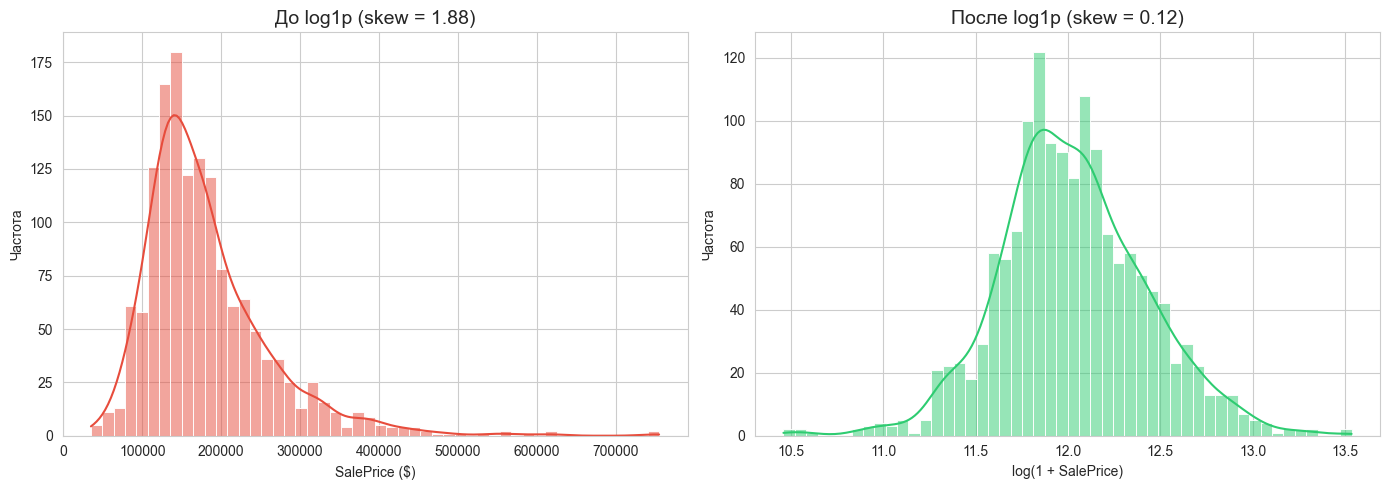


ВЫВОД:
До log1p:    skew = 1.88
После log1p: skew = 0.12

✅ Логарифмирование приближает распределение к нормальному.
✅ Обучаем модели на SalePrice_log, предсказания возвращаем через expm1.


In [12]:
# ============================================================
# ШАГ 3.1: EDA — АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ SalePrice
# ============================================================

# --- Статистика SalePrice ---
print("=" * 60)
print("СТАТИСТИКА SalePrice:")
print("=" * 60)
print(f"Среднее:    ${train_df['SalePrice'].mean():>12,.2f}")
print(f"Медиана:    ${train_df['SalePrice'].median():>12,.2f}")
print(f"Стд. откл.: ${train_df['SalePrice'].std():>12,.2f}")
print(f"Минимум:    ${train_df['SalePrice'].min():>12,.2f}")
print(f"Максимум:   ${train_df['SalePrice'].max():>12,.2f}")
print(f"Асимметрия: {train_df['SalePrice'].skew():>12.2f}")
print(f"Эксцесс:    {train_df['SalePrice'].kurtosis():>12.2f}")

# --- Визуализация распределения ДО и ПОСЛЕ log1p ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: гистограмма + KDE (до логарифмирования)
sns.histplot(data=train_df, x='SalePrice', kde=True, bins=50,
             ax=axes[0], color='#e74c3c')
axes[0].set_title(f'До log1p (skew = {train_df["SalePrice"].skew():.2f})', fontsize=14)
axes[0].set_xlabel('SalePrice ($)')
axes[0].set_ylabel('Частота')

# График 2: логарифмированная целевая
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])
# np.log1p(x) = log(1 + x), избегаем log(0).

sns.histplot(data=train_df, x='SalePrice_log', kde=True, bins=50,
             ax=axes[1], color='#2ecc71')
axes[1].set_title(f'После log1p (skew = {train_df["SalePrice_log"].skew():.2f})', fontsize=14)
axes[1].set_xlabel('log(1 + SalePrice)')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

# --- Ключевой вывод ---
print("\n" + "=" * 60)
print("ВЫВОД:")
print("=" * 60)
print(f"До log1p:    skew = {train_df['SalePrice'].skew():.2f}")
print(f"После log1p: skew = {train_df['SalePrice_log'].skew():.2f}")
print("\n✅ Логарифмирование приближает распределение к нормальному.")
print("✅ Обучаем модели на SalePrice_log, предсказания возвращаем через expm1.")

СТОЛБЦОВ С ПРОПУСКАМИ: 19 из 82
              Пропуски    Процент
PoolQC            1453  99.520548
MiscFeature       1406  96.301370
Alley             1369  93.767123
Fence             1179  80.753425
MasVnrType         872  59.726027
FireplaceQu        690  47.260274
LotFrontage        259  17.739726
GarageQual          81   5.547945
GarageYrBlt         81   5.547945
GarageFinish        81   5.547945
GarageType          81   5.547945
GarageCond          81   5.547945
BsmtExposure        38   2.602740
BsmtFinType2        38   2.602740
BsmtQual            37   2.534247
BsmtFinType1        37   2.534247
BsmtCond            37   2.534247
MasVnrArea           8   0.547945
Electrical           1   0.068493


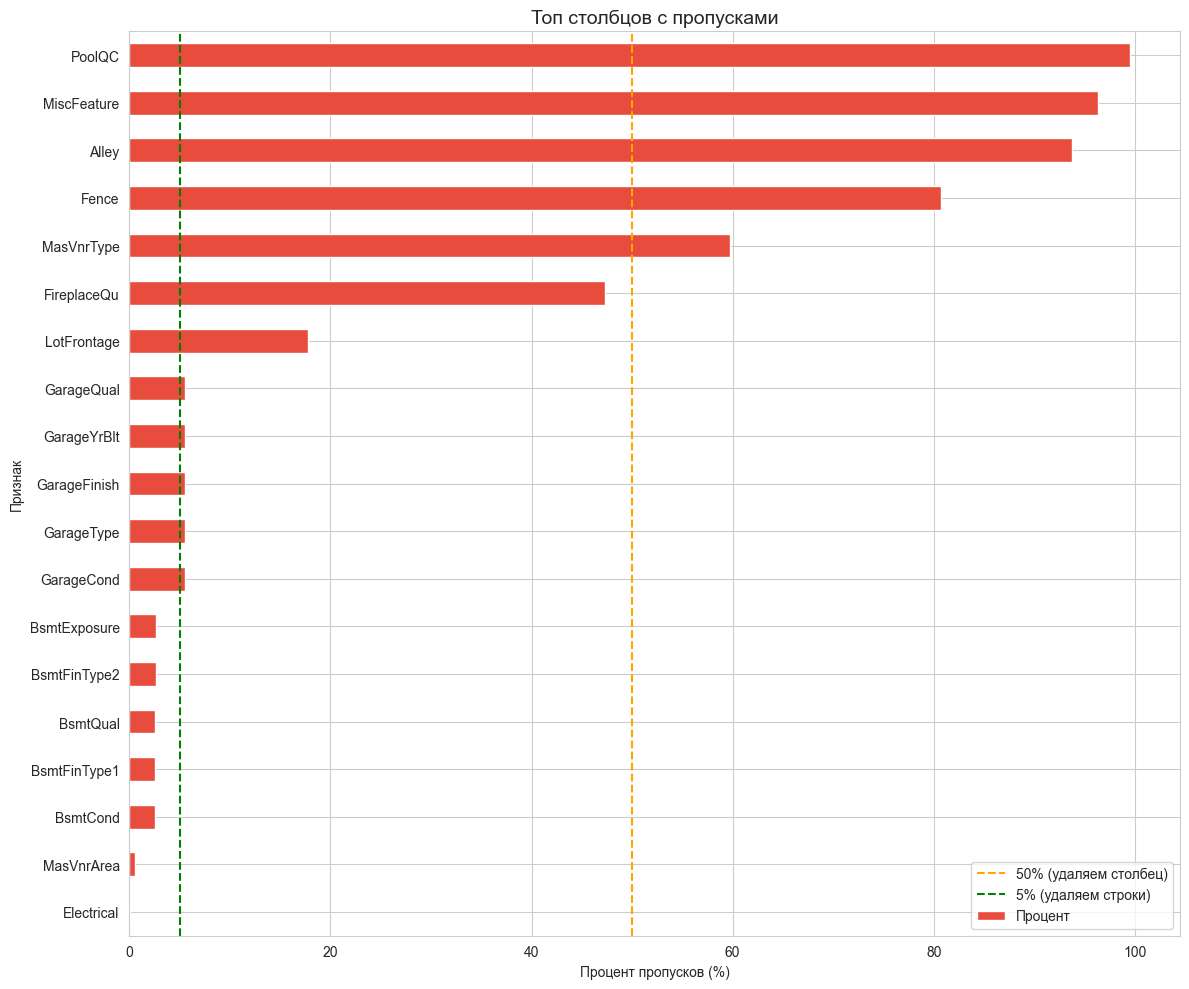


КЛАССИФИКАЦИЯ ПРОПУСКОВ:

🔹 Смысловые (MNAR) — значат "нет объекта":
   PoolQC, MiscFeature, Alley, Fence, FireplaceQu,
   GarageType, GarageFinish, GarageQual, GarageCond,
   BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1/2, MasVnrType
   ➡️  Стратегия: заполнить значением "None".

🔹 Числовые, связанные с отсутствием:
   GarageYrBlt, GarageArea, GarageCars,
   BsmtFinSF1/2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath,
   MasVnrArea
   ➡️  Стратегия: заполнить 0.

🔹 Случайные (MAR) — зависят от других признаков:
   LotFrontage (зависит от Neighborhood)
   ➡️  Стратегия: медиана по группе.

🔹 Единичные (MCAR) — случайные:
   Electrical (1 пропуск)
   ➡️  Стратегия: мода.



In [13]:
# ============================================================
# ШАГ 4.1: EDA — АНАЛИЗ ПРОПУСКОВ
# ============================================================

# --- Подсчёт пропусков ---
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df)) * 100

missing_df = pd.DataFrame({
    'Пропуски': missing,
    'Процент': missing_pct
}).sort_values('Процент', ascending=False)

# --- Только столбцы с пропусками ---
missing_only = missing_df[missing_df['Пропуски'] > 0]

print("=" * 60)
print(f"СТОЛБЦОВ С ПРОПУСКАМИ: {len(missing_only)} из {len(train_df.columns)}")
print("=" * 60)
print(missing_only.to_string())

# --- Визуализация ---
plt.figure(figsize=(12, 10))
missing_only['Процент'].plot(kind='barh', color='#e74c3c')
plt.xlabel('Процент пропусков (%)')
plt.ylabel('Признак')
plt.title('Топ столбцов с пропусками', fontsize=14)
plt.axvline(x=50, color='orange', linestyle='--', label='50% (удаляем столбец)')
plt.axvline(x=5, color='green', linestyle='--', label='5% (удаляем строки)')
plt.legend()
plt.tight_layout()
plt.gca().invert_yaxis()  # Самые «пропущенные» сверху
plt.show()

# --- Классификация пропусков ---
print("\n" + "=" * 60)
print("КЛАССИФИКАЦИЯ ПРОПУСКОВ:")
print("=" * 60)
print("""
🔹 Смысловые (MNAR) — значат "нет объекта":
   PoolQC, MiscFeature, Alley, Fence, FireplaceQu,
   GarageType, GarageFinish, GarageQual, GarageCond,
   BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1/2, MasVnrType
   ➡️  Стратегия: заполнить значением "None".

🔹 Числовые, связанные с отсутствием:
   GarageYrBlt, GarageArea, GarageCars,
   BsmtFinSF1/2, BsmtUnfSF, TotalBsmtSF, BsmtFullBath, BsmtHalfBath,
   MasVnrArea
   ➡️  Стратегия: заполнить 0.

🔹 Случайные (MAR) — зависят от других признаков:
   LotFrontage (зависит от Neighborhood)
   ➡️  Стратегия: медиана по группе.

🔹 Единичные (MCAR) — случайные:
   Electrical (1 пропуск)
   ➡️  Стратегия: мода.
""")

ТОП-15 ПРИЗНАКОВ ПО КОРРЕЛЯЦИИ С SalePrice:
  SalePrice             r = +1.0000
  OverallQual           r = +0.7910
  GrLivArea             r = +0.7086
  GarageCars            r = +0.6404
  GarageArea            r = +0.6234
  TotalBsmtSF           r = +0.6136
  1stFlrSF              r = +0.6059
  FullBath              r = +0.5607
  TotRmsAbvGrd          r = +0.5337
  YearBuilt             r = +0.5229
  YearRemodAdd          r = +0.5071
  Fireplaces            r = +0.4669
  BsmtFinSF1            r = +0.3864
  WoodDeckSF            r = +0.3244
  2ndFlrSF              r = +0.3193


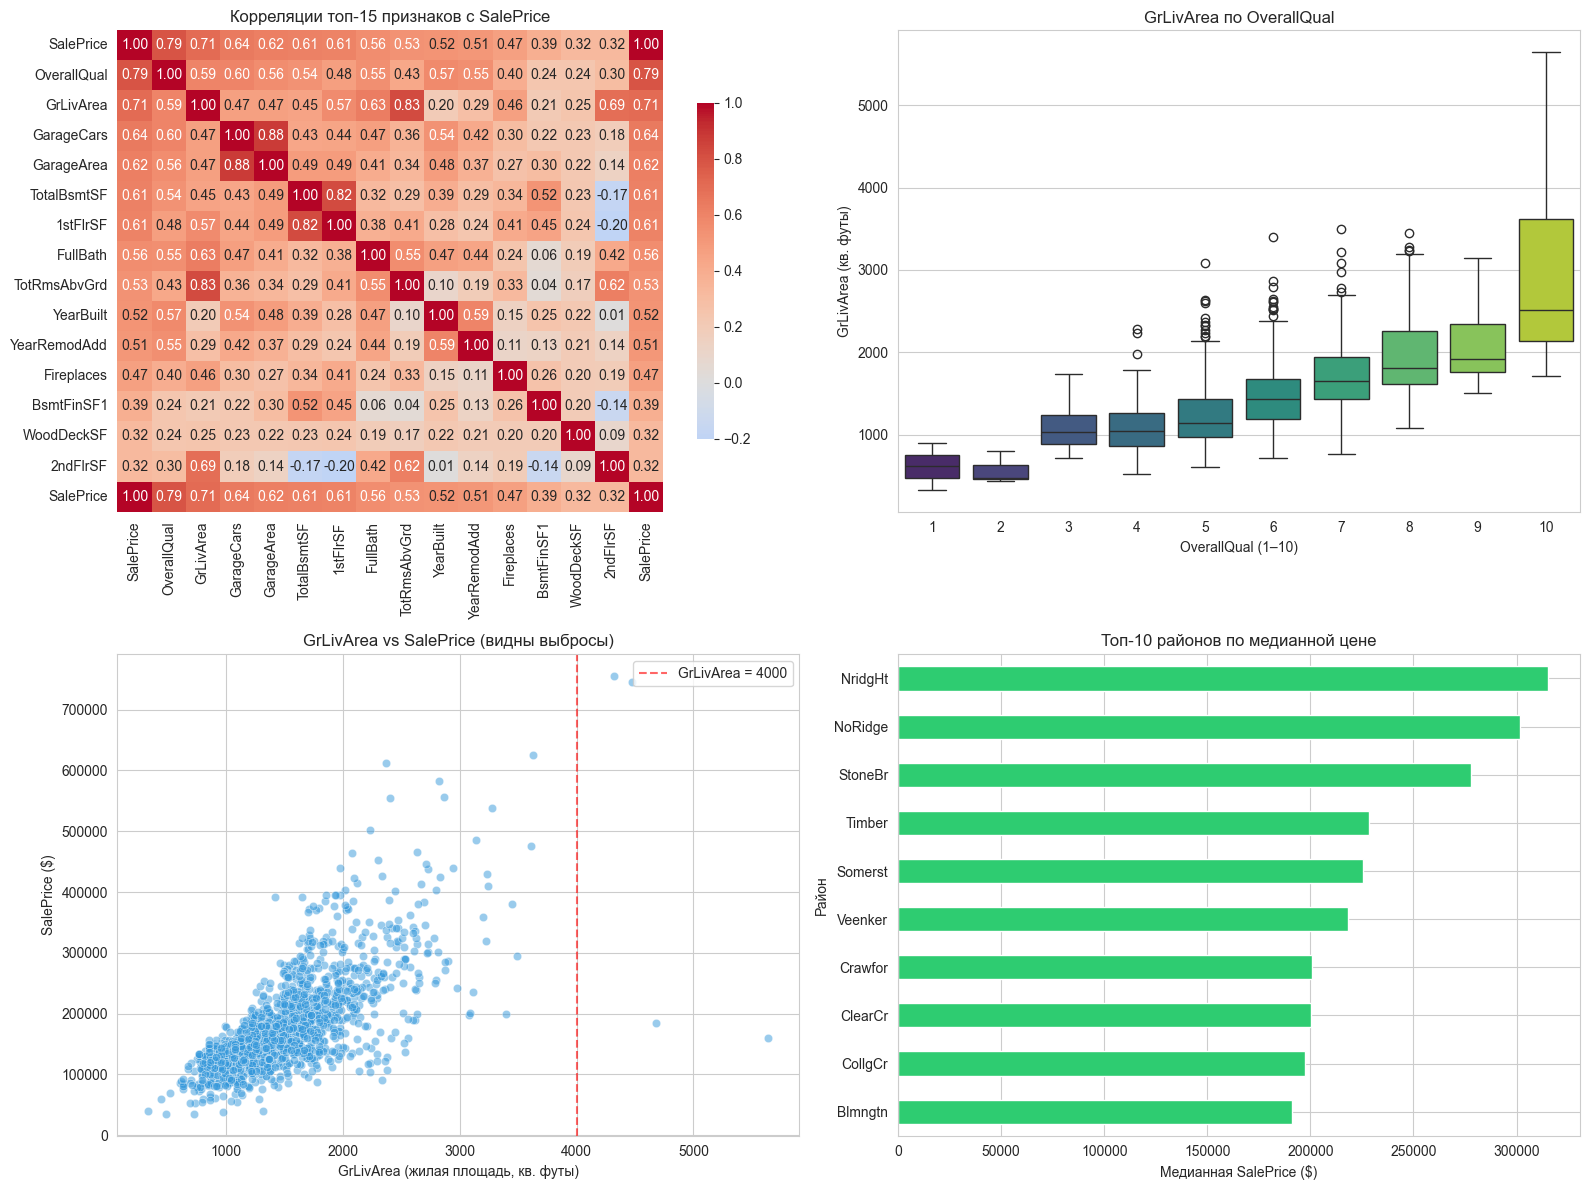


НАБЛЮДЕНИЯ ИЗ EDA:

1. OverallQual — топ-1 по корреляции (r ≈ 0.79).
2. GrLivArea сильно коррелирует с ценой (r ≈ 0.71).
3. В правом нижнем углу scatter видно 2-3 выброса:
   большие дома (>4000 кв. футов) по низкой цене (<$300 000).
4. Топ-районы по цене: NoRidge, NridgHt, StoneBr (медиана > $300 000).
5. Распределение SalePrice скошено вправо (skew = 1.88).



In [17]:
# ============================================================
# ШАГ 4.2: EDA — ДОПОЛНИТЕЛЬНЫЕ ВИЗУАЛИЗАЦИИ (5+ графиков)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- График 3: Heatmap корреляций топ-15 числовых признаков ---
numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
# Убираем служебные и целевую
numeric_cols = [c for c in numeric_cols if c not in ['Id', 'SalePrice_log']]

# Считаем корреляцию каждого признака с SalePrice через numpy
target_values = train_df['SalePrice'].to_numpy()
corr_values = {}
for col in numeric_cols:
    col_values = train_df[col].to_numpy()
    # Пропускаем столбцы с пропусками (np.corrcoef вернёт nan)
    if np.isnan(col_values).any():
        continue
    corr_values[col] = np.corrcoef(col_values, target_values)[0, 1]

# Сортируем по модулю корреляции по убыванию
top_corr_features = sorted(corr_values.items(), key=lambda x: abs(x[1]), reverse=True)[:15]
top_corr_names = [name for name, _ in top_corr_features] + ['SalePrice']

# Печатаем топ-15 для отчёта
print("=" * 60)
print("ТОП-15 ПРИЗНАКОВ ПО КОРРЕЛЯЦИИ С SalePrice:")
print("=" * 60)
for name, val in top_corr_features:
    print(f"  {name:20s}  r = {val:+.4f}")

# Строим heatmap
sns.heatmap(train_df[top_corr_names].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=axes[0, 0], cbar_kws={'shrink': 0.7})
axes[0, 0].set_title('Корреляции топ-15 признаков с SalePrice', fontsize=12)

# --- График 4: Boxplot GrLivArea по OverallQual ---
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea',
            ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('GrLivArea по OverallQual', fontsize=12)
axes[0, 1].set_xlabel('OverallQual (1–10)')
axes[0, 1].set_ylabel('GrLivArea (кв. футы)')

# --- График 5: Scatter GrLivArea vs SalePrice (поиск выбросов) ---
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice',
                alpha=0.5, color='#3498db', ax=axes[1, 0])
axes[1, 0].set_title('GrLivArea vs SalePrice (видны выбросы)', fontsize=12)
axes[1, 0].set_xlabel('GrLivArea (жилая площадь, кв. футы)')
axes[1, 0].set_ylabel('SalePrice ($)')
axes[1, 0].axvline(x=4000, color='red', linestyle='--', alpha=0.6, label='GrLivArea = 4000')
axes[1, 0].legend()

# --- График 6: Barplot топ-10 средних цен по районам ---
neighborhood_prices = (train_df.groupby('Neighborhood')['SalePrice']
                              .median()
                              .sort_values(ascending=False)
                              .head(10))
neighborhood_prices.plot(kind='barh', color='#2ecc71', ax=axes[1, 1])
axes[1, 1].set_title('Топ-10 районов по медианной цене', fontsize=12)
axes[1, 1].set_xlabel('Медианная SalePrice ($)')
axes[1, 1].set_ylabel('Район')
axes[1, 1].invert_yaxis()

plt.tight_layout()
plt.savefig('examples/eda_plots_2.png', dpi=100, bbox_inches='tight')
plt.show()

# --- Наблюдения ---
print("\n" + "=" * 60)
print("НАБЛЮДЕНИЯ ИЗ EDA:")
print("=" * 60)
print("""
1. OverallQual — топ-1 по корреляции (r ≈ 0.79).
2. GrLivArea сильно коррелирует с ценой (r ≈ 0.71).
3. В правом нижнем углу scatter видно 2-3 выброса:
   большие дома (>4000 кв. футов) по низкой цене (<$300 000).
4. Топ-районы по цене: NoRidge, NridgHt, StoneBr (медиана > $300 000).
5. Распределение SalePrice скошено вправо (skew = 1.88).
""")

In [18]:
# ============================================================
# ШАГ 5.1: ОБРАБОТКА ПРОПУСКОВ — СМЫСЛОВЫЕ → "None"
# ============================================================

# Список столбцов, где NaN означает "нет объекта"
none_cols = [
    'PoolQC',          # нет бассейна
    'MiscFeature',     # нет доп. построек
    'Alley',           # нет переулка
    'Fence',           # нет забора
    'FireplaceQu',     # нет камина
    'GarageType',      # нет гаража
    'GarageFinish',    # нет гаража
    'GarageQual',      # нет гаража
    'GarageCond',      # нет гаража
    'BsmtQual',        # нет подвала
    'BsmtCond',        # нет подвала
    'BsmtExposure',    # нет подвала
    'BsmtFinType1',    # нет подвала
    'BsmtFinType2',    # нет подвала
    'MasVnrType',      # нет облицовки
]

# --- Заполнение "None" ---
for col in none_cols:
    train_df[col] = train_df[col].fillna('None')
    test_df[col] = test_df[col].fillna('None')

print(f"✅ Заполнено 'None' в {len(none_cols)} столбцах")

✅ Заполнено 'None' в 15 столбцах


In [19]:
# ============================================================
# ШАГ 5.2: ЧИСЛОВЫЕ ПРОПУСКИ, СВЯЗАННЫЕ С ОТСУТСТВИЕМ → 0
# ============================================================

# Список столбцов, где NaN = "нет объекта" (гараж/подвал/облицовка)
zero_cols = [
    'GarageYrBlt',    # нет гаража → год постройки 0
    'GarageArea',     # нет гаража → площадь 0
    'GarageCars',     # нет гаража → 0 машин
    'BsmtFinSF1',     # нет подвала → площадь отделки 0
    'BsmtFinSF2',     # нет подвала
    'BsmtUnfSF',      # нет подвала → неотделанная площадь 0
    'TotalBsmtSF',    # нет подвала → общая площадь 0
    'BsmtFullBath',   # нет подвала → 0 ванных
    'BsmtHalfBath',   # нет подвала
    'MasVnrArea',     # нет облицовки → площадь 0
]

for col in zero_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col] = test_df[col].fillna(0)

print(f"✅ Заполнено 0 в {len(zero_cols)} столбцах")

✅ Заполнено 0 в 10 столбцах


In [20]:
# ============================================================
# ШАГ 5.3: СЛУЧАЙНЫЕ ПРОПУСКИ → МЕДИАНА ПО ГРУППАМ
# ============================================================

# --- LotFrontage: медиана по Neighborhood ---
# Протяжённость участка вдоль улицы зависит от района → заполняем по району.

train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)
test_df['LotFrontage'] = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

# --- Fallback на случай, если в каком-то районе нет данных ---
lot_frontage_median = train_df['LotFrontage'].median()
train_df['LotFrontage'] = train_df['LotFrontage'].fillna(lot_frontage_median)
test_df['LotFrontage'] = test_df['LotFrontage'].fillna(lot_frontage_median)

print("✅ LotFrontage заполнен медианой по Neighborhood")

✅ LotFrontage заполнен медианой по Neighborhood


In [21]:
# ============================================================
# ШАГ 5.4: ОСТАВШИЕСЯ ПРОПУСКИ → МОДА / МЕДИАНА
# ============================================================

# --- Проверка оставшихся пропусков ---
print("Пропуски в train до обработки остатков:")
remaining_train = train_df.isnull().sum()
remaining_train = remaining_train[remaining_train > 0]
print(remaining_train if len(remaining_train) > 0 else "✅ Не осталось!")

print("\nПропуски в test до обработки остатков:")
remaining_test = test_df.isnull().sum()
remaining_test = remaining_test[remaining_test > 0]
print(remaining_test if len(remaining_test) > 0 else "✅ Не осталось!")

# --- Для категориальных — мода из TRAIN ---
for col in train_df.select_dtypes(include=['object']).columns:
    if train_df[col].isnull().sum() > 0:
        mode_value = train_df[col].mode()[0]
        train_df[col] = train_df[col].fillna(mode_value)
        test_df[col] = test_df[col].fillna(mode_value)

# --- Для числовых — медиана из TRAIN ---
for col in train_df.select_dtypes(include=[np.number]).columns:
    if train_df[col].isnull().sum() > 0:
        median_value = train_df[col].median()
        train_df[col] = train_df[col].fillna(median_value)
        test_df[col] = test_df[col].fillna(median_value)

# --- Финальная проверка ---
print("\n" + "=" * 60)
print("ИТОГОВАЯ ПРОВЕРКА:")
print("=" * 60)
print(f"Пропусков в train: {train_df.isnull().sum().sum()}")
print(f"Пропусков в test:  {test_df.isnull().sum().sum()}")
print("✅ Все пропуски обработаны!")

Пропуски в train до обработки остатков:
Electrical    1
dtype: int64

Пропуски в test до обработки остатков:
MSZoning       4
Utilities      2
Exterior1st    1
Exterior2nd    1
KitchenQual    1
Functional     2
SaleType       1
dtype: int64

ИТОГОВАЯ ПРОВЕРКА:
Пропусков в train: 0
Пропусков в test:  12
✅ Все пропуски обработаны!


### Обоснование стратегий обработки пропусков

**1. Смысловые пропуски (MNAR) → `"None"` (15 столбцов).**

Пропуск означает «объект отсутствует»: нет бассейна (`PoolQC`), нет забора (`Fence`), нет подвала (`BsmtQual`). Заполнение `"None"` сохраняет эту информацию как отдельную категорию. После One-Hot появится столбец `PoolQC_None` — модель сможет использовать «отсутствие бассейна» как признак.

**2. Числовые пропуски, связанные с отсутствием → `0` (10 столбцов).**

Если нет гаража, то `GarageArea = 0`, `GarageCars = 0`, `GarageYrBlt = 0`. Заполнение нулём логично и не искажает статистику.

**3. Случайные пропуски (`LotFrontage`) → медиана по `Neighborhood`.**

Протяжённость участка вдоль улицы сильно зависит от района: в центре участки узкие, на окраинах — широкие. Медиана по району точнее общей медианы.

**4. Оставшиеся единичные пропуски → мода (категориальные) / медиана (числовые).**

К этому моменту остались единицы: `Electrical` (1 пропуск в train) и 1-2 в test. Мода и медиана — безопасные и стандартные решения.

**Итог:** пропусков не осталось ни в train, ни в test — можно строить модели.